# Observados INMET no GEE com falhas preenchidas por Xavier (BR-DWGD)

Este notebook apresenta os resultados da construção dos assets `projects/fcoliveira/assets/observados_inmet`.

**Fluxo** (scripts nesta pasta):
1. `metadados.py`: código da estação, código IBGE, município e UF de cada ponto (junção espacial com a malha do IBGE).
2. `extrair_xavier.py`: amostra a grade BR-DWGD (`projects/sat-io/open-datasets/BR-DWGD`) no pixel de cada estação,
   1961-01-01 a 2020-07-31.
3. `preencher_enviar.py`: período de operação de cada estação (primeiro ao último dia observado), preenchimento das
   falhas com Xavier (`preenchido = 1`) e envio ao GEE em lotes, sem bucket, com expansão no servidor para uma
   feição por estação-dia.
4. `orquestrar.py` e `descricoes.py`: exportação final, descrição dos assets e limpeza dos temporários.

In [1]:
import json
from pathlib import Path

import ee
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sys
sys.path.insert(0, str(Path.cwd().parent / "codigo"))  # executar a partir de notebooks/
from caminhos import CACHE, COMPACTOS, DADOS, PASTA_EE, PROJETO_EE
from caminhos import RES_OBS as RES
VARS = ["Tmax", "Tmin", "RH", "Rs", "u2", "pr"]
NOMES = {"Tmax": "Tmax (°C)", "Tmin": "Tmin (°C)", "RH": "UR (%)", "Rs": "Rs (MJ m⁻² d⁻¹)",
         "u2": "u₂ (m s⁻¹)", "pr": "P (mm d⁻¹)"}
ESCALA = {"Tmax": (0.00106815, 15.0), "Tmin": (0.00106815, 15.0), "RH": (0.39370079, -0.393701),
          "Rs": (0.15708661, -0.057087), "u2": (0.05905512, -0.059055), "pr": (0.00686666, 225.0)}
plt.rcParams.update({"font.size": 9, "figure.dpi": 110})
ee.Initialize(project=PROJETO_EE)

## 1. Resumo por variável

In [2]:
linhas = []
for v in VARS:
    r = pd.read_csv(RES / f"resumo_{v}.csv", dtype={"cod_ibge": str})
    validos = r.dias.sum() - r.sem_valor.sum()
    linhas.append({"variável": v, "estações": len(r), "municípios": r.cod_ibge.nunique(), "UFs": r.uf.nunique(),
                   "estação-dias (M)": round(validos / 1e6, 2), "observados (%)": round(100 * r.observados.sum() / validos, 1),
                   "preenchidos (%)": round(100 * r.preenchidos.sum() / validos, 1),
                   "anos medianos por estação": round((r.dias / 365.25).median(), 1),
                   "início mais antigo": r.inicio.min()})
resumo = pd.DataFrame(linhas).set_index("variável")
resumo

,estações,municípios,UFs,estação-dias (M),observados (%),preenchidos (%),anos medianos por estação,início mais antigo
variável,,,,,,,,
Tmax,1164,814,27,9.46,83.9,16.1,13.4,1961-01-01
Tmin,1159,809,27,9.40,83.9,16.1,13.4,1961-01-01
RH,1142,798,27,8.99,82.3,17.7,13.2,1961-01-01
Rs,1037,737,27,8.14,82.9,17.1,13.1,1961-01-01
u2,1126,790,27,8.80,77.1,22.9,13.1,1961-01-01
pr,13259,4120,27,120.69,89.7,10.3,20.9,1961-01-01


## 2. Localização das estações e proporção de dias preenchidos

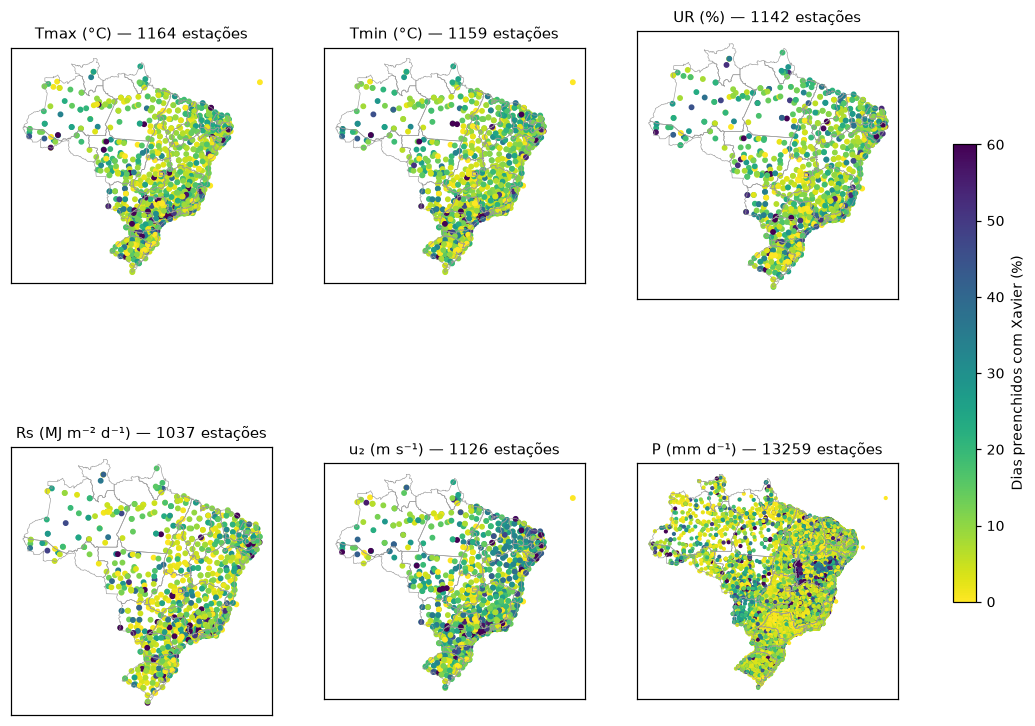

In [3]:
br = gpd.read_file(DADOS / "uf.geojson")  # contorno dos estados (IBGE)
fig, axs = plt.subplots(2, 3, figsize=(13, 9))
for ax, v in zip(axs.flat, VARS):
    r = pd.read_csv(RES / f"resumo_{v}.csv")
    r["pct"] = 100 * r.preenchidos / (r.dias - r.sem_valor)
    br.boundary.plot(ax=ax, color="0.6", lw=0.4)
    sc = ax.scatter(r.lon, r.lat, c=r.pct, s=3 if v == "pr" else 8, cmap="viridis_r", vmin=0, vmax=60)
    ax.set_title(f"{NOMES[v]} — {len(r)} estações", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(sc, ax=axs, shrink=0.6, label="Dias preenchidos com Xavier (%)")
plt.show()

## 3. Validação: Xavier × observado nos dias com observação

Antes de usar a grade para preencher falhas, compara-se o valor de Xavier no pixel da estação com o valor
observado, nos dias em que ambos existem. Note que essas estações foram usadas na interpolação da grade, de
modo que a concordância é otimista em relação a um ponto independente.

In [4]:
def metricas(o, x):
    ok = ~np.isnan(o) & ~np.isnan(x)
    o, x = o[ok], x[ok]
    return {"n (M)": round(ok.sum() / 1e6, 2), "viés": round(float(np.mean(x - o)), 3),
            "RMSE": round(float(np.sqrt(np.mean((x - o) ** 2))), 3), "r": round(float(np.corrcoef(o, x)[0, 1]), 4)}


val = {}
for v in VARS:
    o = np.load(CACHE / f"obs_{v}.npy", mmap_mode="r")
    x = np.load(CACHE / f"xav_{v}.npy", mmap_mode="r")
    passo = 7 if v == "pr" else 1  # amostra semanal para a precipitação (volume)
    oo = np.array(o[::passo]); xx = np.array(x[::passo]).astype(np.float32) * ESCALA[v][0] + ESCALA[v][1]
    if v == "pr":
        xx = np.clip(xx, 0, None)
    val[v] = metricas(oo.ravel(), xx.ravel())
pd.DataFrame(val).T

,n (M),viés,RMSE,r
Tmax,7.93,-0.050,0.525,0.9938
Tmin,7.89,-0.061,0.545,0.9927
RH,7.39,-0.650,5.413,0.9183
Rs,6.74,-0.132,1.674,0.9577
u2,6.78,-0.085,0.497,0.8828
pr,15.44,0.010,6.030,0.8257


## 4. Exemplos de séries com os dias preenchidos destacados

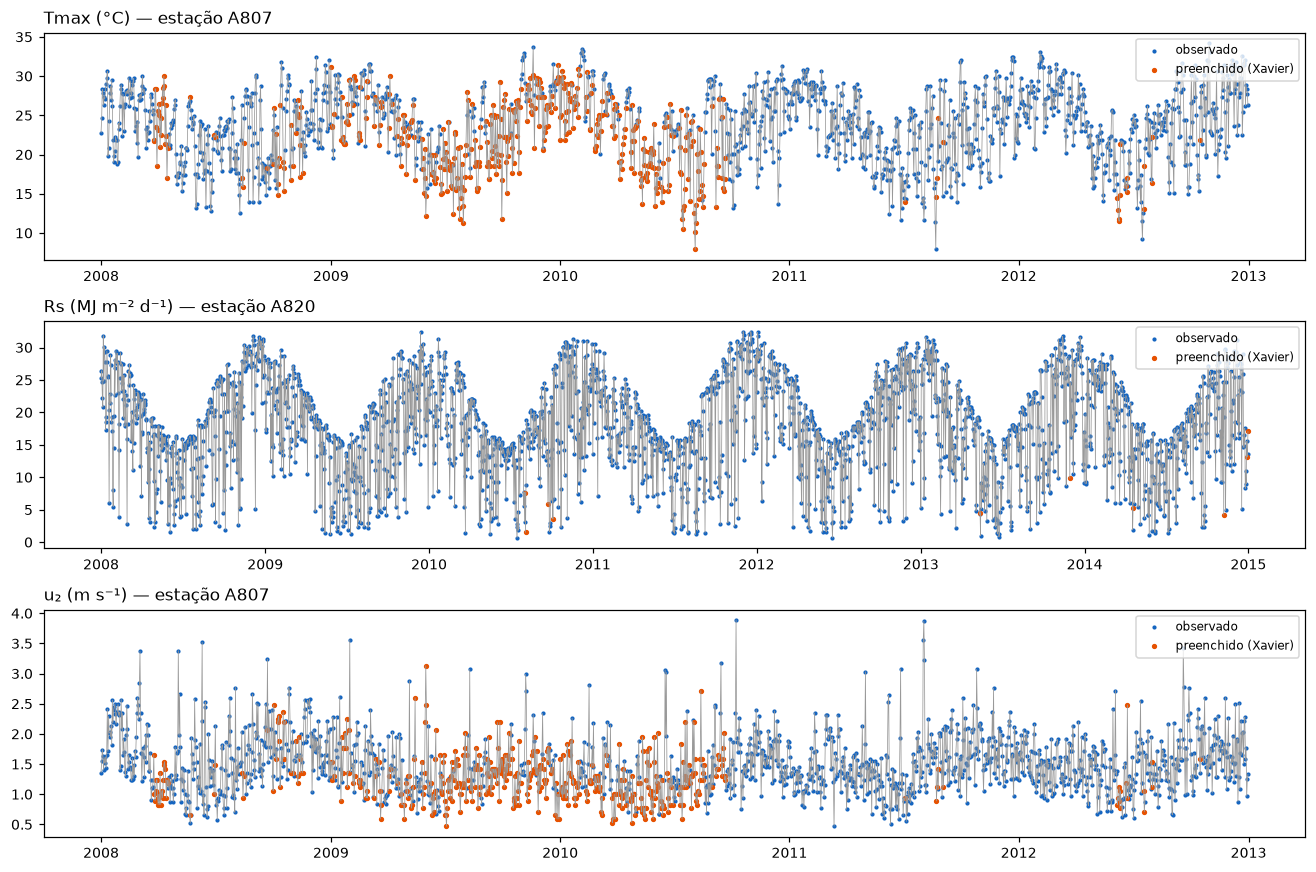

In [5]:
def serie_local(v, cod):
    c = pd.read_parquet(COMPACTOS / f"compacto_{v}.parquet", filters=[("cod_estacao", "==", cod)])
    regs = []
    for _, r in c.iterrows():
        vals = r.v.split(","); d0 = pd.Timestamp(r.inicio)
        for i, (s, f) in enumerate(zip(vals, r.f)):
            if f != "9":
                regs.append((d0 + pd.Timedelta(days=i), float(s), int(f)))
    return pd.DataFrame(regs, columns=["data", "valor", "preenchido"]).set_index("data")


fig, axs = plt.subplots(3, 1, figsize=(12, 8))
for ax, (v, cod, ini, fim) in zip(axs, [("Tmax", "A807", "2008", "2012"), ("Rs", "A820", "2008", "2014"),
                                        ("u2", "A807", "2008", "2012")]):
    s = serie_local(v, cod).loc[ini:fim]
    ax.plot(s.index, s.valor, color="0.6", lw=0.5)
    ax.scatter(s.index[s.preenchido == 0], s.valor[s.preenchido == 0], s=3, color="#1565c0", label="observado")
    ax.scatter(s.index[s.preenchido == 1], s.valor[s.preenchido == 1], s=6, color="#e65100", label="preenchido (Xavier)")
    ax.set_title(f"{NOMES[v]} — estação {cod}", loc="left"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

## 5. Assets no Google Earth Engine

In [6]:
PASTA = PASTA_EE
info = []
for a in ee.data.listAssets({"parent": PASTA})["assets"]:
    if a["type"] != "TABLE":
        continue
    det = ee.data.getAsset(a["name"])
    p = det.get("properties", {})
    info.append({"asset": a["name"].split("/")[-1], "título": p.get("title"), "estações": p.get("n_estacoes"),
                 "% preenchido": p.get("pct_preenchido"), "tamanho (MB)": round(int(det.get("sizeBytes", 0)) / 1e6, 1),
                 "atualizado": det.get("updateTime", "")[:19]})
pd.DataFrame(info)

,asset,título,estações,% preenchido,tamanho (MB),atualizado
0,RH,Observados INMET - Umidade relativa média diár...,1142,17.75,37.6,2026-10-16T19:52:48
1,Rs,Observados INMET - Radiação solar global diária,1037,17.14,36.9,2026-10-16T19:52:57
2,Tmax,Observados INMET - Temperatura máxima diária d...,1164,16.09,36.7,2026-10-16T19:52:29
3,Tmin,Observados INMET - Temperatura mínima diária d...,1159,16.11,41.9,2026-10-16T19:52:38
4,u2,Observados INMET - Velocidade média diária do ...,1126,22.92,37.9,2026-10-16T19:53:05


### Exemplo de uso em Python: série de uma estação lida do asset

In [7]:
tab = ee.FeatureCollection(f"{PASTA}/Tmax")
serie = (tab.filter(ee.Filter.eq("cod_estacao", "A807"))
            .filterDate("2010-01-01", "2010-03-01"))
df = ee.data.computeFeatures({"expression": serie, "fileFormat": "PANDAS_DATAFRAME"})
df[["cod_estacao", "cod_ibge", "municipio", "uf", "data", "valor", "preenchido"]].sort_values("data").head(10)

,cod_estacao,cod_ibge,municipio,uf,data,valor,preenchido
18,A807,4106902,Curitiba,PR,2010-01-01,21.9,1
19,A807,4106902,Curitiba,PR,2010-01-02,29.7,1
20,A807,4106902,Curitiba,PR,2010-01-03,25.1,1
21,A807,4106902,Curitiba,PR,2010-01-04,30.6,1
22,A807,4106902,Curitiba,PR,2010-01-05,29.1,1
23,A807,4106902,Curitiba,PR,2010-01-06,29.9,1
24,A807,4106902,Curitiba,PR,2010-01-07,28.5,1
25,A807,4106902,Curitiba,PR,2010-01-08,21.9,1
26,A807,4106902,Curitiba,PR,2010-01-09,24.3,1
27,A807,4106902,Curitiba,PR,2010-01-10,22.6,1


### Exemplo: estações e dias preenchidos por município (código IBGE)

In [8]:
pr_pr = (ee.FeatureCollection(f"{PASTA}/RH").filter(ee.Filter.eq("uf", "PR"))
         .reduceColumns(ee.Reducer.mean().group(1, "cod_ibge"), ["preenchido", "cod_ibge"]))
pd.DataFrame(pr_pr.get("groups").getInfo()).rename(columns={"mean": "fração preenchida"}).head(10)

,cod_ibge,fração preenchida
0,4103909,0.276910
1,4104204,0.000765
2,4104303,0.052194
3,4104808,0.922830
4,4104907,0.129675
5,4105607,0.121768
6,4105706,0.044529
7,4105805,0.521680
8,4106407,0.000000
9,4106902,0.113680


### Descrição gravada no asset (exibida no Code Editor)

In [9]:
print(ee.data.getAsset(f"{PASTA}/Tmax")["properties"]["description"])

# Observados INMET — Temperatura máxima diária do ar (Tmax)

Série diária observada em **1164 estações meteorológicas do INMET (automáticas e convencionais) usadas por Xavier et al. (2022)**, de 01/01/1961 a 31/07/2020, com as falhas
preenchidas pela grade **BR-DWGD** (Xavier et al., 2022; `projects/sat-io/open-datasets/BR-DWGD`).

**Unidade:** °C
**Período de cada estação:** do primeiro ao último dia com observação (limitado a 31/07/2020).
**Preenchimento:** 16.1% dos 9,458,958 estação-dias vieram da grade de Xavier
(pixel de 0,1° que contém a estação; estações em pixels mascarados do litoral usam a média focal de 2 pixels).

## Campos (uma feição por estação-dia)
| campo | descrição |
|---|---|
| `cod_estacao` | código da estação (INMET, p. ex. A807; ou código do pluviômetro) |
| `cod_ibge` | código IBGE (7 dígitos) do município da estação |
| `municipio`, `uf` | município e unidade da federação |
| `lat`, `lon`, `alt` | coordenadas (graus) e altitude (m) |
| `data` | data (AAAA-MM-D